# 02 · Experimentos: qué estrategias ganan y por qué

Cada experimento compara varias **variantes** (condiciones) y repite cada una con **50
semillas**, para separar lo robusto de la suerte. Se definen en `experiments/*.toml` y se
ejecutan con:

```
split-steal experiment experiments/ruido.toml
split-steal compare results/experiments/ruido --top 15
split-steal plot results/experiments/ruido
```

Aquí se leen los `summary.csv` versionados (una fila por variante y estrategia). Métricas
principales: `rank_mean` (posición media final, 1 = campeón), `rank_ci95` (margen del
intervalo de confianza del 95 %), `title_rate` (% de torneos ganados).

In [1]:
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

from split_steal import plots
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)
from split_steal.experiment import compare

EXP = Path("../results/experiments")
summaries = {name: pd.read_csv(EXP / name / "summary.csv")
             for name in ["ruido", "perdon_optimo", "formatos", "tentacion"]}
{name: f"{s.variant.nunique()} variantes" for name, s in summaries.items()}

{'ruido': '4 variantes',
 'perdon_optimo': '14 variantes',
 'formatos': '4 variantes',
 'tentacion': '4 variantes'}

## 1. El ruido: cuando hay errores

`experiments/ruido.toml`: el torneo canónico con una probabilidad creciente de que cada
jugada salga al revés (un error, un malentendido).

- Sin ruido, las cooperadoras "justas" (Gradual, TitForTat...) dominan.
- Con errores, **MimicMajority** (juega lo que el rival ha hecho más veces) pasa a liderar:
  un error aislado no cambia la mayoría, así que lo ignora, pero castiga a quien traiciona de
  forma persistente.
- TitForTat, que solo mira la última jugada, aguanta hasta el 5 % y se hunde al 10 %.

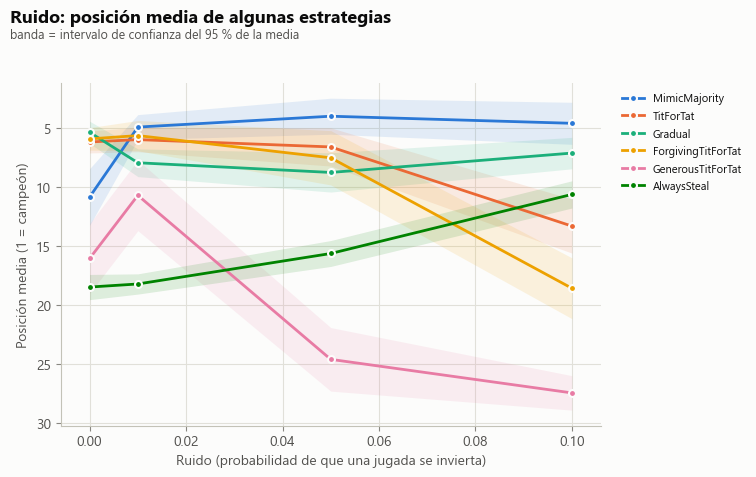

In [2]:
s = summaries["ruido"]
plots.plot_sweep(s, x="noise", metric="rank_mean",
                 strategies=["MimicMajority", "TitForTat", "Gradual", "ForgivingTitForTat",
                             "GenerousTitForTat", "AlwaysSteal"],
                 title="Ruido: posición media de algunas estrategias");

A medida que hay más errores se coopera menos en general, y la traición pura gana terreno:

In [3]:
(s.groupby("noise")
   .agg(cooperacion_media=("coop_rate", "mean"), puntos_por_ronda=("points_per_round", "mean"))
   .join(s[s.strategy == "AlwaysSteal"].set_index("noise")["rank_mean"].rename("posicion_AlwaysSteal")))

,cooperacion_media,puntos_por_ronda,posicion_AlwaysSteal
noise,,,
0.00,0.64,2.39,18.48
0.01,0.57,2.27,18.22
0.05,0.50,2.17,15.64
0.10,0.48,2.15,10.64


## 2. ¿Cuánto conviene perdonar?

`experiments/perdon_optimo.toml`: ForgivingTitForTat perdona una traición con probabilidad
`p` (p = 0 es TitForTat; p = 1 es cooperar siempre). Todos contra todos, 9 estrategias amables
y 3 traicioneras, con y sin ruido.

La teoría (Nowak y Sigmund) da p = 1/3 como el perdón **máximo** que una población puede
permitirse sin que la invadan los traidores. Aquí lo mejor es **perdonar poco (10-20 %)**, y
a partir de 1/3 empeora. Además, cuanto más perdona, mejor le va a AlwaysSteal.

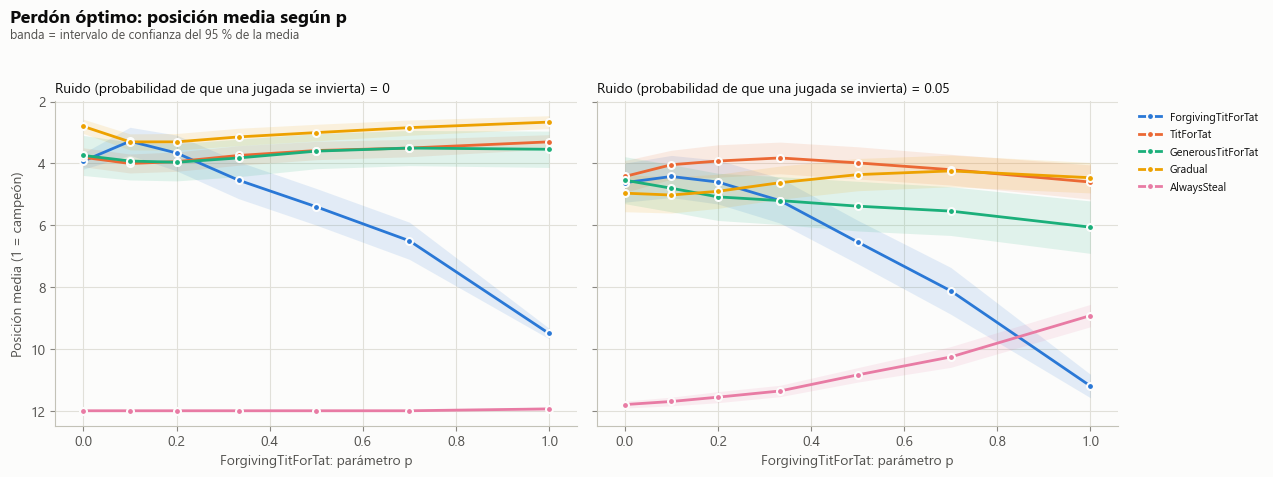

In [4]:
plots.plot_sweep(summaries["perdon_optimo"], x="ForgivingTitForTat.p", facet="noise",
                 strategies=["ForgivingTitForTat", "TitForTat", "GenerousTitForTat", "Gradual",
                             "AlwaysSteal"],
                 title="Perdón óptimo: posición media según p");

## 3. El formato del torneo cambia quién gana

`experiments/formatos.toml`: ligas con ascensos frente a todos contra todos, con y sin ruido.
En todos contra todos sin ruido **Gradual gana casi siempre**; en ligas los títulos se
reparten entre muchas, porque en la Liga 1 las cooperadoras empatan en todo y decide el
sorteo. Una estrategia puede dominar un formato y no ganar nunca en el otro.

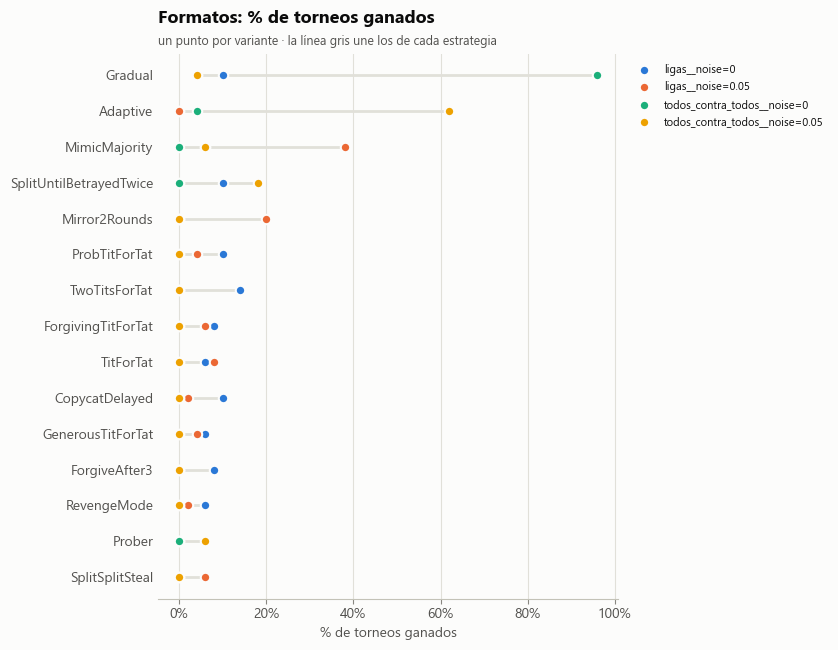

In [5]:
plots.plot_variants(summaries["formatos"], metric="title_rate",
                    title="Formatos: % de torneos ganados");

## 4. Cuando traicionar tienta más

`experiments/tentacion.toml`: se cambia T, los puntos por robar a quien coopera (normal: 5).
Cuanto más vale una traición, más caro sale tardar en responderla: **TitForTat** (responde
ya) mejora y **MimicMajority** (necesita una mayoría de traiciones para castigar) se hunde.
No hay una estrategia "mejor" en abstracto: depende del entorno.

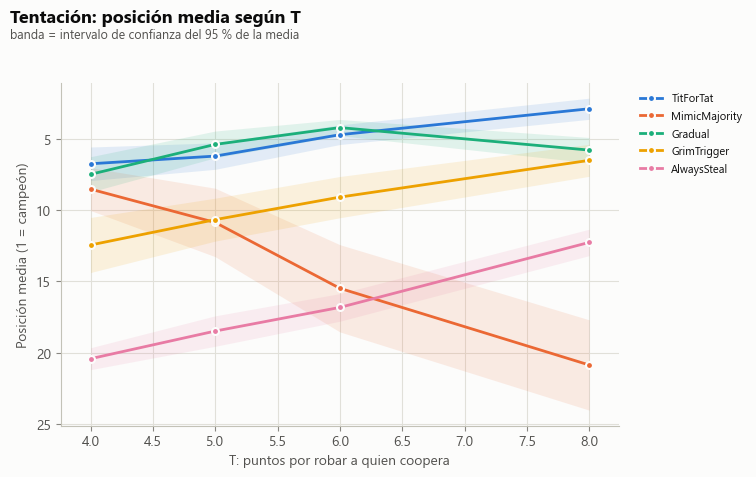

In [6]:
plots.plot_sweep(summaries["tentacion"], x="payoff.T", metric="rank_mean",
                 strategies=["TitForTat", "MimicMajority", "Gradual", "GrimTrigger", "AlwaysSteal"],
                 title="Tentación: posición media según T");

## 5. Tabla completa para explorar

`compare` pone una fila por estrategia y una columna por variante con la métrica que elijas
(aquí, el % de títulos con ruido creciente).

In [7]:
compare([EXP / "ruido"], metric="title_rate").head(10)

column,noise=0,noise=0.01,noise=0.05,noise=0.1
strategy,,,,
MimicMajority,0.06,0.16,0.38,0.34
Gradual,0.10,0.06,0.04,0.20
Mirror2Rounds,0.00,0.12,0.20,0.00
ForgivingTitForTat,0.08,0.14,0.06,0.02
TitForTat,0.06,0.12,0.08,0.04
ProbTitForTat,0.10,0.10,0.04,0.00
SplitUntilBetrayedTwice,0.10,0.04,0.00,0.08
RevengeMode,0.06,0.08,0.02,0.06
GenerousTitForTat,0.06,0.10,0.04,0.00


## Haz tu propio experimento

Copia uno de `experiments/*.toml`, cambia `[base]` (formato, estrategias, rondas...) y
`[sweep]` (qué variar), y ejecútalo con `split-steal experiment`. La guía de usuario
(`docs/GUIA_USUARIO.md`) explica todas las opciones.